Dimensiones del dataset: (20640, 9)
Valores nulos por columna:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
Dimensiones después de filtrar tope censurado: (19648, 9)

--- RESULTADOS REGRESIÓN LINEAL ---
Pendiente (coef_): 0.3994
Intercepto:        0.4511
MSE:               0.5650
RMSE:              0.7516
R²:                0.4107


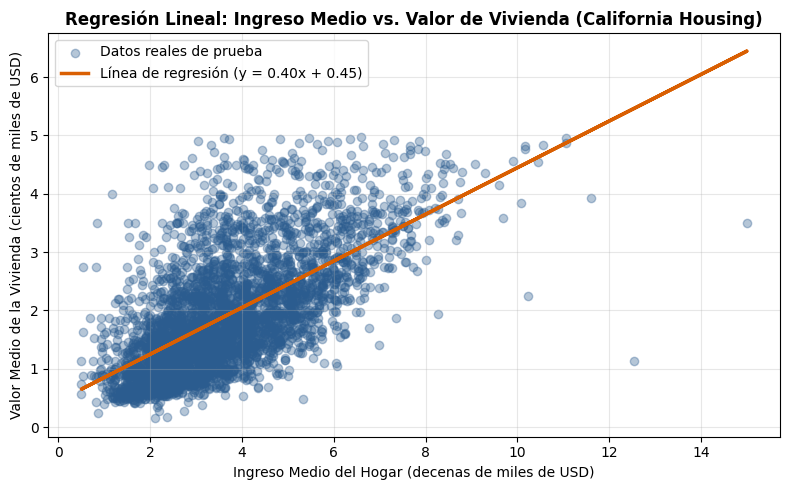

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Carga e inspección del conjunto de datos California Housing
housing = fetch_california_housing(as_frame=True)
df_housing = housing.frame.copy()

print("Dimensiones del dataset:", df_housing.shape)
print("Valores nulos por columna:\n", df_housing.isnull().sum())

# 2. Filtrado de registros censurados en el tope superior (MedHouseVal == 5.00001)
df_clean = df_housing[df_housing['MedHouseVal'] < 5.0].copy()
print("Dimensiones después de filtrar tope censurado:", df_clean.shape)

# 3. Definición de matriz X (ingreso medio MedInc) y variable objetivo continua y (valor vivienda)
X = df_clean[['MedInc']]
y = df_clean['MedHouseVal']

# 4. División estratificada/aleatoria 80% entrenamiento y 20% prueba con semilla fija
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 5. Entrenamiento y evaluación del modelo LinearRegression
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)
y_pred = modelo_lr.predict(X_test)

pendiente = modelo_lr.coef_[0]
intercepto = modelo_lr.intercept_
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n--- RESULTADOS REGRESIÓN LINEAL ---")
print(f"Pendiente (coef_): {pendiente:.4f}")
print(f"Intercepto:        {intercepto:.4f}")
print(f"MSE:               {mse:.4f}")
print(f"RMSE:              {rmse:.4f}")
print(f"R²:                {r2:.4f}")

# 6. Visualización con línea de regresión
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.35, color='#2b5c8f', label='Datos reales de prueba')
plt.plot(X_test, y_pred, color='#d95f02', linewidth=2.5,
         label=f'Línea de regresión (y = {pendiente:.2f}x + {intercepto:.2f})')
plt.title('Regresión Lineal: Ingreso Medio vs. Valor de Vivienda (California Housing)', fontweight='bold')
plt.xlabel('Ingreso Medio del Hogar (decenas de miles de USD)')
plt.ylabel('Valor Medio de la Vivienda (cientos de miles de USD)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Dimensiones: (200, 3)
Nulos: 0 | Duplicados: 0

--- EVALUACIÓN DE VALORES DE k ---
k = 2 | Inercia: 243.05 | Silhouette Score: 0.3833
k = 3 | Inercia: 145.95 | Silhouette Score: 0.4911
k = 4 | Inercia: 72.71 | Silhouette Score: 0.5929
k = 5 | Inercia: 28.23 | Silhouette Score: 0.6794
k = 6 | Inercia: 25.20 | Silhouette Score: 0.6396

--- CENTROIDES EN ESCALA ORIGINAL (k=5) ---
   Ingreso_Anual_kUSD  Puntaje_Gasto_1_100  Tamano
0               25.96                78.15      40
1               88.44                19.06      35
2               23.67                20.72      39
3               85.75                81.26      35
4               54.65                51.57      51


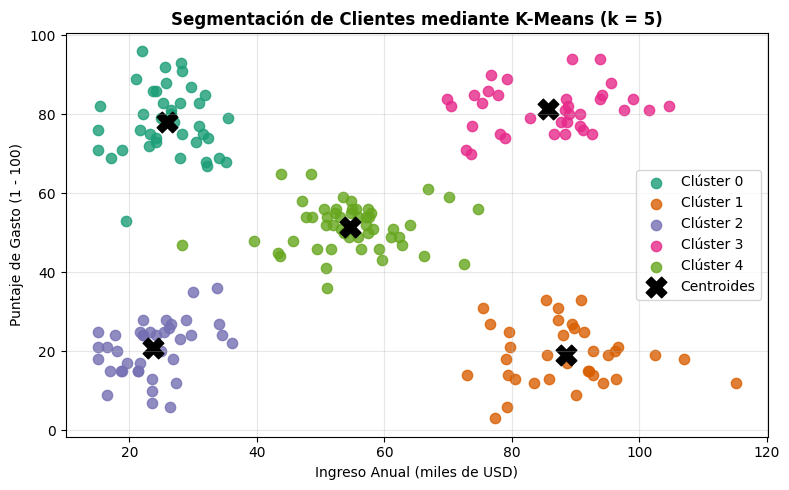

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Generación de dataset equivalente a Mall Customers (200 clientes, semilla 42)
np.random.seed(42)
ingresos = np.concatenate([
    np.random.normal(25, 6, 40),
    np.random.normal(26, 6, 40),
    np.random.normal(55, 8, 50),
    np.random.normal(86, 10, 35),
    np.random.normal(88, 10, 35)
])
puntaje_gasto = np.concatenate([
    np.random.normal(20, 7, 40),
    np.random.normal(79, 8, 40),
    np.random.normal(50, 7, 50),
    np.random.normal(82, 8, 35),
    np.random.normal(18, 7, 35)
])

df_clientes = pd.DataFrame({
    'ClienteID': np.arange(1, 201),
    'Ingreso_Anual_kUSD': np.round(np.clip(ingresos, 15, 137), 1),
    'Puntaje_Gasto_1_100': np.round(np.clip(puntaje_gasto, 1, 99), 0).astype(int)
})

print("Dimensiones:", df_clientes.shape)
print("Nulos:", df_clientes.isnull().sum().sum(), "| Duplicados:", df_clientes.duplicated().sum())

# 2. Escalamiento estándar (StandardScaler)
features = ['Ingreso_Anual_kUSD', 'Puntaje_Gasto_1_100']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clientes[features])

# 3. Evaluación de k (2 a 6) con Método del Codo (Inercia) y Silhouette Score
print("\n--- EVALUACIÓN DE VALORES DE k ---")
inercias = []
siluetas = []
rango_k = range(2, 7)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_scaled)
    inercias.append(km.inertia_)
    sil = silhouette_score(X_scaled, etiquetas)
    siluetas.append(sil)
    print(f"k = {k} | Inercia: {km.inertia_:.2f} | Silhouette Score: {sil:.4f}")

# 4. Entrenamiento final con k = 5 (óptimo en Mall Customers)
k_optimo = 5
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df_clientes['Cluster'] = kmeans_final.fit_predict(X_scaled)

# Centroides transformados de vuelta a escala original
centroides_orig = scaler.inverse_transform(kmeans_final.cluster_centers_)
df_centroides = pd.DataFrame(centroides_orig, columns=features)
df_centroides['Tamano'] = df_clientes['Cluster'].value_counts().sort_index().values
print("\n--- CENTROIDES EN ESCALA ORIGINAL (k=5) ---")
print(df_centroides.round(2))

# 5. Visualización de clústeres y centroides
plt.figure(figsize=(8, 5))
colores = ['#1b9e77', '#d95f02', '#7570b3', '#e7298a', '#66a61e']
for c in range(k_optimo):
    subset = df_clientes[df_clientes['Cluster'] == c]
    plt.scatter(subset['Ingreso_Anual_kUSD'], subset['Puntaje_Gasto_1_100'],
                s=55, color=colores[c], label=f'Clúster {c}', alpha=0.8)

plt.scatter(centroides_orig[:, 0], centroides_orig[:, 1],
            s=220, c='black', marker='X', label='Centroides')
plt.title('Segmentación de Clientes mediante K-Means (k = 5)', fontweight='bold')
plt.xlabel('Ingreso Anual (miles de USD)')
plt.ylabel('Puntaje de Gasto (1 - 100)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()